# Trajectory Generation Comparison

Generate random smooth trajectories using different methods, visualize them
as 3D plots, and render MuJoCo videos with the rodent and a moving target
sphere to evaluate which method produces the most suitable training
trajectories for the walk-rear moving-target task.

In [26]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import plotly.graph_objects as go
from matplotlib.backends.backend_agg import FigureCanvasAgg
from scipy.interpolate import CubicSpline
from scipy.ndimage import gaussian_filter1d

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import walk_rear

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [48]:
# ============ TRAJECTORY SETTINGS ============
EPISODE_LENGTH = 500       # Number of timesteps
SEED = 21                  # Base random seed
N_EXAMPLES = 3             # Trajectories to generate per method

# Per-axis amplitude (meters) — controls the spatial extent of trajectories
AMP_X = 0.1                # Horizontal (forward/back)
AMP_Y = 0.1                # Horizontal (left/right)
AMP_Z = 0.2               # Vertical (rearing height)
AMPLITUDES = np.array([AMP_X, AMP_Y, AMP_Z])

# ============ CONSTRAINTS ============
# Minimum z value relative to trajectory start (meters).
# 0.0  = target never dips below its starting height.
# -0.02 = allow 2 cm below start.
# None = no constraint.
Z_MIN_OFFSET = 0.0

# ============ RENDERING ============
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50
CAMERA_NAME = "close_profile-rodent"
TARGET_SPHERE_RADIUS = 0.015
TARGET_RGBA = [1.0, 0.0, 0.0, 0.4]

## Trajectory Generation Functions

Each function returns an array of shape `(T, 3)` starting at the origin.
The caller offsets the trajectory to the skull's initial position.

In [49]:
def fourier_trajectory(
    rng: np.random.Generator,
    T: int,
    amplitudes: np.ndarray,
    n_freq: int = 5,
) -> np.ndarray:
    """Sum of low-frequency sinusoids with random amplitudes and phases.

    Produces globally smooth, quasi-periodic paths. The amplitude of each
    frequency component decays as 1/freq, keeping high-frequency content small.
    """
    t = np.linspace(0, 1, T)
    freqs = np.arange(1, n_freq + 1)
    traj = np.zeros((T, 3))
    for dim in range(3):
        # Random amplitudes scaled by 1/freq for smoothness
        amps = rng.standard_normal(n_freq) * amplitudes[dim] / freqs
        phases = rng.uniform(0, 2 * np.pi, n_freq)
        for k in range(n_freq):
            traj[:, dim] += amps[k] * np.sin(
                2 * np.pi * freqs[k] * t + phases[k]
            )
    # Offset so trajectory starts at origin
    traj -= traj[0]
    return traj


def waypoint_spline_trajectory(
    rng: np.random.Generator,
    T: int,
    amplitudes: np.ndarray,
    n_waypoints: int = 8,
) -> np.ndarray:
    """Cubic spline interpolation through random waypoints.

    Generates K random waypoints, then fits a natural cubic spline to produce
    a smooth path. Intuitive control over trajectory complexity via waypoint count.
    """
    wp_times = np.linspace(0, 1, n_waypoints)
    waypoints = np.zeros((n_waypoints, 3))
    # First waypoint at origin, rest are random
    for dim in range(3):
        waypoints[1:, dim] = rng.standard_normal(n_waypoints - 1) * amplitudes[dim]
    t = np.linspace(0, 1, T)
    traj = np.zeros((T, 3))
    for dim in range(3):
        cs = CubicSpline(wp_times, waypoints[:, dim], bc_type="natural")
        traj[:, dim] = cs(t)
    traj -= traj[0]
    return traj


def ou_trajectory(
    rng: np.random.Generator,
    T: int,
    amplitudes: np.ndarray,
    theta: float = 2.0,
    dt: float = 0.02,
) -> np.ndarray:
    """Ornstein-Uhlenbeck process (mean-reverting random walk).

    Naturally bounded around the origin with controllable drift speed (theta)
    and noise magnitude (amplitudes). Good for exploration-like targets that
    don't wander too far.
    """
    sigma = amplitudes * np.sqrt(2 * theta)  # Scale so stationary std ~ amplitudes
    traj = np.zeros((T, 3))
    for t in range(1, T):
        noise = rng.standard_normal(3)
        traj[t] = traj[t - 1] + (-theta * traj[t - 1] * dt + sigma * np.sqrt(dt) * noise)
    return traj


def smoothed_random_walk(
    rng: np.random.Generator,
    T: int,
    amplitudes: np.ndarray,
    sigma_smooth: float = 30.0,
) -> np.ndarray:
    """Gaussian-smoothed cumulative random walk (scipy version).

    Generates a raw random walk, then applies Gaussian smoothing to remove
    high-frequency jitter. Simple but produces diffusive (unbounded) paths.
    The smoothing width controls trajectory smoothness.
    """
    step_scale = amplitudes / np.sqrt(T)
    raw_steps = rng.standard_normal((T, 3)) * step_scale
    cumsum = np.cumsum(raw_steps, axis=0)
    traj = gaussian_filter1d(cumsum, sigma=sigma_smooth, axis=0)
    traj -= traj[0]
    # Clamp each axis to [-amplitude, +amplitude]
    traj = np.clip(traj, -amplitudes, amplitudes)
    return traj


def smoothed_random_walk_jax(
    rng: np.random.Generator,
    T: int,
    amplitudes: np.ndarray,
    sigma_smooth: float = 30.0,
) -> np.ndarray:
    """Gaussian-smoothed cumulative random walk (JAX-compatible version).

    Same algorithm as smoothed_random_walk but uses JAX operations only:
    jax.random for noise, jnp.cumsum, and 1D convolution with a Gaussian
    kernel instead of scipy.ndimage.gaussian_filter1d.

    This is the version that can run inside jax.jit at environment reset.
    """
    # Use the numpy rng to get a JAX key (bridge between numpy and JAX rng)
    jax_seed = int(rng.integers(0, 2**31))
    key = jax.random.PRNGKey(jax_seed)

    amplitudes_jax = jnp.array(amplitudes)
    step_scale = amplitudes_jax / jnp.sqrt(T)
    raw_steps = jax.random.normal(key, shape=(T, 3)) * step_scale
    cumsum = jnp.cumsum(raw_steps, axis=0)

    # Build Gaussian kernel (truncated at 3*sigma)
    radius = int(jnp.ceil(3 * sigma_smooth))
    x = jnp.arange(-radius, radius + 1, dtype=jnp.float32)
    kernel = jnp.exp(-0.5 * (x / sigma_smooth) ** 2)
    kernel = kernel / kernel.sum()

    # Convolve each axis independently (mode="same" via manual padding)
    pad_width = len(kernel) // 2
    traj = jnp.zeros((T, 3))
    for dim in range(3):
        padded = jnp.pad(cumsum[:, dim], pad_width, mode="edge")
        smoothed = jnp.convolve(padded, kernel, mode="valid")
        traj = traj.at[:, dim].set(smoothed[:T])

    traj = traj - traj[0]
    # Clamp each axis to [-amplitude, +amplitude]
    traj = jnp.clip(traj, -amplitudes_jax, amplitudes_jax)
    return np.array(traj)


# Registry of all methods
METHODS = {
    "Fourier": fourier_trajectory,
    "Waypoint Spline": waypoint_spline_trajectory,
    "Ornstein-Uhlenbeck": ou_trajectory,
    "Smoothed Random Walk": smoothed_random_walk,
    "Smoothed Random Walk (JAX)": smoothed_random_walk_jax,
}

print(f"Defined {len(METHODS)} trajectory generation methods")

Defined 5 trajectory generation methods


## Generate Example Trajectories

In [50]:
# Generate N_EXAMPLES trajectories per method
all_trajectories = {}  # {method_name: [traj1, traj2, ...]}

for method_name, gen_fn in METHODS.items():
    trajs = []
    for i in range(N_EXAMPLES):
        rng = np.random.default_rng(SEED + i)
        traj = gen_fn(rng, EPISODE_LENGTH, AMPLITUDES)
        # Apply z-floor constraint (relative to start, which is at origin)
        if Z_MIN_OFFSET is not None:
            traj[:, 2] = np.maximum(traj[:, 2], Z_MIN_OFFSET)
        trajs.append(traj)
    all_trajectories[method_name] = trajs
    print(f"{method_name}: {N_EXAMPLES} trajectories, shape {trajs[0].shape}")
    # Print stats for first trajectory
    t0 = trajs[0]
    print(f"  Range: x=[{t0[:,0].min():.3f}, {t0[:,0].max():.3f}]  "
          f"y=[{t0[:,1].min():.3f}, {t0[:,1].max():.3f}]  "
          f"z=[{t0[:,2].min():.3f}, {t0[:,2].max():.3f}]")
    # Compute speed stats
    speeds = np.linalg.norm(np.diff(t0, axis=0), axis=1)
    print(f"  Speed: mean={speeds.mean():.4f}  max={speeds.max():.4f}  "
          f"std={speeds.std():.4f}")

Fourier: 3 trajectories, shape (500, 3)
  Range: x=[-0.183, 0.129]  y=[-0.098, 0.164]  z=[0.000, 0.170]
  Speed: mean=0.0035  max=0.0075  std=0.0017
Waypoint Spline: 3 trajectories, shape (500, 3)
  Range: x=[-0.179, 0.183]  y=[-0.197, 0.084]  z=[0.000, 0.454]
  Speed: mean=0.0050  max=0.0094  std=0.0022
Ornstein-Uhlenbeck: 3 trajectories, shape (500, 3)
  Range: x=[-0.304, 0.236]  y=[-0.176, 0.195]  z=[0.000, 0.430]
  Speed: mean=0.0506  max=0.1891  std=0.0289
Smoothed Random Walk: 3 trajectories, shape (500, 3)
  Range: x=[-0.059, 0.012]  y=[-0.021, 0.058]  z=[0.000, 0.200]
  Speed: mean=0.0008  max=0.0015  std=0.0004
Smoothed Random Walk (JAX): 3 trajectories, shape (500, 3)
  Range: x=[-0.007, 0.069]  y=[-0.007, 0.052]  z=[0.000, 0.123]
  Speed: mean=0.0009  max=0.0024  std=0.0005


## 3D Path Visualization

Interactive 3D plots showing the full trajectory path for each method.
All examples for a given method are shown on the same plot.

In [51]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

for method_name, trajs in all_trajectories.items():
    fig = go.Figure()
    for i, traj in enumerate(trajs):
        T = len(traj)
        fig.add_trace(go.Scatter3d(
            x=traj[:, 0], y=traj[:, 1], z=traj[:, 2],
            mode="lines",
            line=dict(color=colors[i % len(colors)], width=3),
            name=f"seed {SEED + i}",
            hovertemplate="t=%{customdata}<br>x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}",
            customdata=np.arange(T),
        ))
        # Start marker
        fig.add_trace(go.Scatter3d(
            x=[traj[0, 0]], y=[traj[0, 1]], z=[traj[0, 2]],
            mode="markers", marker=dict(size=5, color="green", symbol="circle"),
            name=f"start {i}", showlegend=False,
        ))
        # End marker
        fig.add_trace(go.Scatter3d(
            x=[traj[-1, 0]], y=[traj[-1, 1]], z=[traj[-1, 2]],
            mode="markers", marker=dict(size=5, color="red", symbol="x"),
            name=f"end {i}", showlegend=False,
        ))

    fig.update_layout(
        title=dict(text=f"{method_name} — {N_EXAMPLES} trajectories", font=dict(size=14)),
        scene=dict(
            xaxis_title="X (m)",
            yaxis_title="Y (m)",
            zaxis_title="Z (m)",
            aspectmode="data",
        ),
        width=750, height=550,
        legend=dict(x=0.01, y=0.99, font=dict(size=10)),
        margin=dict(l=0, r=0, t=50, b=0),
    )
    fig.show()

## Speed Profiles

Compare how the target speed varies over time for each method.

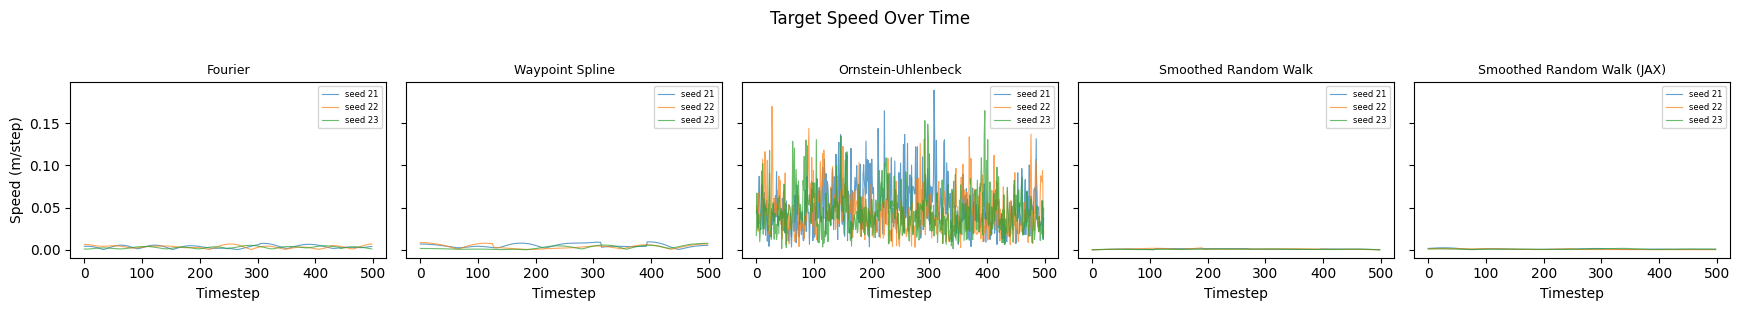

In [52]:
n_methods = len(METHODS)
fig, axes = plt.subplots(1, n_methods, figsize=(3.5 * n_methods, 3), sharey=True)

for ax, (method_name, trajs) in zip(axes, all_trajectories.items()):
    for i, traj in enumerate(trajs):
        speeds = np.linalg.norm(np.diff(traj, axis=0), axis=1)
        ax.plot(speeds, alpha=0.7, lw=0.8, label=f"seed {SEED + i}")
    ax.set_title(method_name, fontsize=9)
    ax.set_xlabel("Timestep")
    if ax is axes[0]:
        ax.set_ylabel("Speed (m/step)")
    ax.legend(fontsize=6)

plt.suptitle("Target Speed Over Time", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## Load MuJoCo Model for Rendering

Create a walk-rear environment to get the rodent model with arena.
The target marker is converted from a box to a sphere.

In [53]:
# Create a walk_rear env just to get the compiled MuJoCo model
wr_cfg = walk_rear.default_config()
wr_cfg.target_x = 0.0
wr_cfg.target_y = 0.0
wr_cfg.target_z = 0.05
wr_cfg.mujoco_impl = "warp"
wr_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML

wr_env = walk_rear.WalkRear(config=wr_cfg)
model = wr_env.mj_model
data = mujoco.MjData(model)

# Convert target_box from box to sphere for nicer rendering
target_geom_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_GEOM, "target_box")
model.geom_type[target_geom_id] = mujoco.mjtGeom.mjGEOM_SPHERE
model.geom_size[target_geom_id] = [TARGET_SPHERE_RADIUS, 0, 0]
model.geom_rgba[target_geom_id] = TARGET_RGBA

# Get skull position at the default pose (rodent at rest)
mujoco.mj_forward(model, data)
skull_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "skull-rodent")
skull_xpos_default = data.xpos[skull_body_id].copy()

cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    cam_id = 0

print(f"Model loaded: {model.nq} qpos, {model.nbody} bodies, {model.ngeom} geoms")
print(f"Default skull xpos: ({skull_xpos_default[0]:.4f}, {skull_xpos_default[1]:.4f}, {skull_xpos_default[2]:.4f})")
print(f"Target sphere geom id: {target_geom_id}")

Model loaded: 74 qpos, 68 bodies, 102 geoms
Default skull xpos: (0.0875, 0.0000, 0.0652)
Target sphere geom id: 0


## Render Videos

For each method, render the first trajectory as a video showing the rodent
at its default pose with the target sphere moving along the trajectory path.

In [54]:
def _stamp_frame(frame, text, fontsize=14):
    """Draw text onto a frame using matplotlib."""
    h, w = frame.shape[:2]
    dpi = 100
    fig = plt.Figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(frame)
    ax.text(
        10, 28, text, fontsize=fontsize, color="white",
        fontweight="bold", family="monospace",
        bbox=dict(facecolor="black", alpha=0.5, pad=2, edgecolor="none"),
    )
    ax.axis("off")
    canvas.draw()
    buf = np.frombuffer(canvas.buffer_rgba(), dtype=np.uint8).reshape(h, w, 4)
    plt.close(fig)
    return buf[:, :, :3]


def render_trajectory(model, data, trajectory, cam_id, target_geom_id, method_name):
    """Render a video of the rodent at default pose with moving target."""
    renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
    frames = []

    for t in range(len(trajectory)):
        # Reset rodent to default pose
        mujoco.mj_forward(model, data)

        # Move target sphere to current trajectory position
        data.geom_xpos[target_geom_id] = trajectory[t]

        renderer.update_scene(data, camera=cam_id)
        frame = renderer.render().copy()
        frames.append(_stamp_frame(frame, f"{method_name}  t={t}"))

    renderer.close()
    return frames

In [55]:
# Render first trajectory for each method
for method_name, trajs in all_trajectories.items():
    # Offset trajectory to start at the default skull position
    traj = trajs[1] + skull_xpos_default

    print(f"Rendering {method_name}...")
    frames = render_trajectory(model, data, traj, cam_id, target_geom_id, method_name)

    print(f"  {method_name} — {len(frames)} frames")
    media.show_video(frames, fps=RENDER_FPS)

Rendering Fourier...
  Fourier — 500 frames


This browser does not support the video tag.


Rendering Waypoint Spline...
  Waypoint Spline — 500 frames


This browser does not support the video tag.


Rendering Ornstein-Uhlenbeck...
  Ornstein-Uhlenbeck — 500 frames


This browser does not support the video tag.


Rendering Smoothed Random Walk...
  Smoothed Random Walk — 500 frames


This browser does not support the video tag.


Rendering Smoothed Random Walk (JAX)...
  Smoothed Random Walk (JAX) — 500 frames


This browser does not support the video tag.


## Side-by-Side Summary

| Method | Characteristics | Bounded? | JAX-friendly? |
|--------|----------------|----------|---------------|
| **Fourier** | Globally smooth, quasi-periodic. Amplitude decays with frequency. | Inherently bounded (finite sum of sinusoids) | Yes (sin/cos) |
| **Waypoint Spline** | Smooth through waypoints, piecewise cubic. Complexity controlled by waypoint count. | No hard bounds (spline can overshoot) | Needs custom impl |
| **Ornstein-Uhlenbeck** | Mean-reverting, exploration-like. Stays near origin. | Statistically bounded (mean-reverting) | Yes (simple recurrence) |
| **Smoothed Random Walk** | Diffusive, smooth via Gaussian filter. Simple but can drift far. | Unbounded (diffusive) | No (scipy) |
| **Smoothed Random Walk (JAX)** | Same as above but uses `jnp.convolve` with Gaussian kernel. Drop-in for training. | Unbounded (diffusive) | **Yes** |